# Gibbs-posterior experiment for Corollary 3.4

This notebook runs the Gibbs-posterior experiment from the paper. It uses the same data model, predictors, parameters, prior, and noise settings as the uniform-posterior experiment. Only the posterior changes.

For quadratic loss, the Gibbs posterior is

$$
\rho_{\rm Gibbs}(d\theta)
=
\frac{\exp\{-\lambda_N\widehat{\mathcal L}_N(\theta)\}\,\pi(d\theta)}
{\int_\Theta \exp\{-\lambda_N\widehat{\mathcal L}_N(\vartheta)\}\,\pi(d\vartheta)},
\qquad
\lambda_N=\frac{\sqrt N}{2L(\ln N)^r}.
$$

We calculate its posterior mean $\theta_\star=\mathbb E_{\rho_{\rm Gibbs}}\theta$ (MEP) and compare the squared error $\|\theta_\star-\theta_{\rm true}\|_2^2$ with Corollary 3.4.

## 1. Imports

NumPy and SciPy handle the calculations, pandas handles tables, and Matplotlib makes the figures. `Decimal` is used for the very large $\bar N$ values (around $10^{29}$ and $10^{50}$), where regular floating-point numbers are not precise enough to compare neighboring integers.


In [1]:
from dataclasses import asdict, dataclass, replace
from decimal import Decimal, ROUND_FLOOR, localcontext
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.polynomial.legendre import leggauss
from scipy.optimize import brentq
from scipy.special import logsumexp

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:.9g}")


## 2. Settings

The main experiment uses $N\in\{500,1000,2000,4000,8000,16000,32000,64000\}$ and 40 independent data sets for each noise case. We also run 1000 new data sets at $N_g=4$. The base seed is `20260725`.

The prior is $\pi=U([0.6,1.4]^2)$, centered at $\theta_{\rm true}=(1,1)$. We set $\sigma=0.2$ for Corollary 3.4. The bounded input and output noise ranges are $[-0.05,0.05]$ and $[-0.005,0.005]$. For unbounded noise, we use a Rademacher part of size $0.0125$, Gaussian standard deviation $0.0000625$, and output scale $0.25$.

The Gibbs integral uses 11 Gauss--Legendre nodes in each of three intervals per parameter, giving $33^2=1089$ nodes. We use 160 impulse-response lags and 160 burn-in steps for the data model.


In [2]:
@dataclass(frozen=True)
class Settings:
    """All numerical choices used by the paper experiment."""

    seed: int = 20260725
    sample_sizes: tuple[int, ...] = (
        500,
        1000,
        2000,
        4000,
        8000,
        16000,
        32000,
        64000,
    )
    monte_carlo_trials: int = 40
    N_g: int = 4
    N_g_trials: int = 1000
    burnin: int = 160

    prior_center: tuple[float, float] = (1.0, 1.0)
    prior_half_width: float = 0.40
    auxiliary_sigma: float = 0.20

    bounded_input_half_width: float = 0.05
    bounded_output_half_width: float = 0.005
    innovation_bound: float = 0.05

    unbounded_rademacher_amplitude: float = 0.0125
    unbounded_gaussian_sigma: float = 0.0000625
    unbounded_output_scale_ratio: float = 0.25

    point_delta: float = 0.05
    quadrature_order_per_panel: int = 11
    quadrature_central_radius: float = 0.08
    impulse_horizon: int = 160


settings = Settings()
OUTPUT_DIR = Path.cwd() / "gibbs_detailed_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("sample sizes =", settings.sample_sizes)
print("main independent realizations per regime =", settings.monte_carlo_trials)
print("independent N_g=4 realizations per regime =", settings.N_g_trials)
print("output directory =", OUTPUT_DIR)


sample sizes = (500, 1000, 2000, 4000, 8000, 16000, 32000, 64000)
main independent realizations per regime = 40
independent N_g=4 realizations per regime = 1000
output directory = /workspace/scratch/13d3f8c1a0f2/deliverables/gibbs_posterior_fully_explained/gibbs_detailed_outputs


## 3. Data model and predictor

The data come from the model in the paper:

$$
\mathbf x_g(t+1)=A_g\mathbf x_g(t)+K_g\mathbf e_g(t),
\qquad
\begin{bmatrix}\mathbf y(t)\\\mathbf u(t)\end{bmatrix}
=C_g\mathbf x_g(t)+\mathbf e_g(t),
\qquad
\mathbf e_g(t)=\begin{bmatrix}\mathbf v(t)\\\mathbf u(t)\end{bmatrix}.
$$

Here $(n_x,n_u,n_y)=(3,2,2)$ and

$$
A_g=\begin{bmatrix}0.25&0&0\\0&0.20&0\\0&0&0.125\end{bmatrix},
\quad
K_g=\begin{bmatrix}0&0&0.02&0\\0&0&0&0.02\\0&0&0.70&0.63\end{bmatrix},
\quad
C_g=\begin{bmatrix}0.70&0&0\\0&0.70&0\\0&0&0\\0&0&0\end{bmatrix}.
$$

The predictor is

$$
\widehat{\mathbf x}(t+1)
=\widehat A_\theta\widehat{\mathbf x}(t)+K_g\mathbf w(t),
\qquad
\widehat{\mathbf y}_\theta(t\mid0)=\widehat C\widehat{\mathbf x}(t),
\qquad
\widehat{\mathbf x}(0)=0,
$$

where $\mathbf w(t)=[\mathbf y^{\mathsf T}(t),\mathbf u^{\mathsf T}(t)]^{\mathsf T}$ and $\widehat C$ is the first two rows of $C_g$. The first two columns of $K_g$ are zero, so the code uses $B\mathbf u(t)$ with $B$ taken from the last two columns.

Only $\widehat A_\theta$ depends on the two parameters:

$$
\widehat A_\theta
=A_g+(\theta_1-1)D_1+(\theta_2-1)D_2
=\begin{bmatrix}
0.25&0&3.700(\theta_1-1)\\
0&0.20&3.404(\theta_2-1)\\
0&0&0.125
\end{bmatrix}.
$$

At $\theta_{\rm true}=(1,1)$, this equals $A_g$. The eigenvalues stay at $0.25$, $0.20$, and $0.125$ for all parameters in the prior.


In [3]:
@dataclass(frozen=True)
class System:
    """State-space matrices and the two learned directions in A_theta."""

    A_g: np.ndarray
    D: np.ndarray
    B: np.ndarray
    C: np.ndarray

    @property
    def state_dim(self) -> int:
        return int(self.A_g.shape[0])

    @property
    def input_dim(self) -> int:
        return int(self.B.shape[1])

    @property
    def output_dim(self) -> int:
        return int(self.C.shape[0])

    @property
    def innovation_dim(self) -> int:
        return self.input_dim + self.output_dim

    def A_theta(self, theta: np.ndarray) -> np.ndarray:
        """Return A_g + sum_j (theta_j-1) D_j."""

        theta = np.asarray(theta, dtype=float)
        return self.A_g + np.einsum("j,jab->ab", theta - 1.0, self.D)


def make_system() -> System:
    """Create the fixed three-state example from the paper."""

    directions = np.zeros((2, 3, 3), dtype=float)
    directions[0, 0, 2] = 3.700
    directions[1, 1, 2] = 3.404
    return System(
        A_g=np.diag([0.25, 0.20, 0.125]).astype(float),
        D=directions,
        B=np.array(
            [[0.02, 0.00], [0.00, 0.02], [0.70, 0.63]], dtype=float
        ),
        C=np.array(
            [[0.70, 0.00, 0.00], [0.00, 0.70, 0.00]], dtype=float
        ),
    )


### Set up the system matrices

We create `system`, `K_g`, and `C_g`, then check the dimensions, the true parameter, and the eigenvalues at the prior corners.


In [4]:
system = make_system()
A_g = system.A_g
D_1, D_2 = system.D
B = system.B
C = system.C
K_g = np.hstack((np.zeros((system.state_dim, system.output_dim)), B))
C_g = np.vstack((C, np.zeros((system.input_dim, system.state_dim))))
theta_true = np.asarray(settings.prior_center, dtype=float)

prior_corners = np.array(
    [[a, b] for a in (0.6, 1.4) for b in (0.6, 1.4)], dtype=float
)
prior_corner_radii = np.array(
    [max(abs(np.linalg.eigvals(system.A_theta(theta)))) for theta in prior_corners]
)

assert system.state_dim == 3 and system.input_dim == 2 and system.output_dim == 2
assert np.allclose(system.A_theta(theta_true), A_g)
assert np.allclose(prior_corner_radii, 0.25)
assert np.linalg.norm(A_g @ A_g, ord="fro") > 0.0

print("A_g =\n", A_g)
print("D_1 =\n", D_1)
print("D_2 =\n", D_2)
print("K_g =\n", K_g)
print("C_g =\n", C_g)
print("theta_true =", theta_true)
print("spectral radius over the prior =", prior_corner_radii.max())


A_g =
 [[0.25  0.    0.   ]
 [0.    0.2   0.   ]
 [0.    0.    0.125]]
D_1 =
 [[0.  0.  3.7]
 [0.  0.  0. ]
 [0.  0.  0. ]]
D_2 =
 [[0.    0.    0.   ]
 [0.    0.    3.404]
 [0.    0.    0.   ]]
K_g =
 [[0.   0.   0.02 0.  ]
 [0.   0.   0.   0.02]
 [0.   0.   0.7  0.63]]
C_g =
 [[0.7 0.  0. ]
 [0.  0.7 0. ]
 [0.  0.  0. ]
 [0.  0.  0. ]]
theta_true = [1. 1.]
spectral radius over the prior = 0.25


## 4. Bounded and unbounded noise

Inputs $\mathbf u$ and output noise $\mathbf v$ are independent across time and coordinates. In case B, they are uniform:

$$
u_i(t)\sim U[-0.05,0.05],
\qquad
v_i(t)\sim U[-0.005,0.005].
$$

Their variances are $0.05^2/3$ and $0.005^2/3$. In case U, we use

$$
u_i(t)=0.0125R_{u,i}(t)+0.0000625Z_{u,i}(t),
$$

$$
v_i(t)=0.25\left(0.0125R_{v,i}(t)+0.0000625Z_{v,i}(t)\right),
$$

where $R$ is Rademacher (equal to $-1$ or $1$) and $Z$ is standard Gaussian. Thus $\operatorname{Var}(u_i)=0.0125^2+0.0000625^2$ and $\operatorname{Var}(v_i)=0.25^2\operatorname{Var}(u_i)$.

The code uses these formulas for the variances and a seeded random generator for the data.


In [5]:
def innovation_variances(
    regime: str, settings: Settings
) -> tuple[float, float]:
    """Return one-coordinate input and output-noise variances."""

    if regime == "bounded":
        return (
            settings.bounded_input_half_width**2 / 3.0,
            settings.bounded_output_half_width**2 / 3.0,
        )
    if regime == "unbounded":
        input_variance = (
            settings.unbounded_rademacher_amplitude**2
            + settings.unbounded_gaussian_sigma**2
        )
        return (
            input_variance,
            settings.unbounded_output_scale_ratio**2 * input_variance,
        )
    raise ValueError(regime)


def sample_rademacher_gaussian(
    rng: np.random.Generator,
    shape: tuple[int, ...],
    amplitude: float,
    sigma: float,
) -> np.ndarray:
    """Sample independent coordinates X=amplitude*R+sigma*Z."""

    signs = 2.0 * rng.integers(0, 2, size=shape) - 1.0
    return amplitude * signs + sigma * rng.normal(size=shape)


innovation_variance_table = pd.DataFrame(
    [
        {
            "case": regime[0].upper(),
            "Var(u_i(t))": innovation_variances(regime, settings)[0],
            "Var(v_i(t))": innovation_variances(regime, settings)[1],
        }
        for regime in ("bounded", "unbounded")
    ]
)
innovation_variance_table


,case,Var(u_i(t)),Var(v_i(t))
0,B,0.000833333333,8.33333333e-06
1,U,0.000156253906,9.76586914e-06


## 5. Simulate one data set

`simulate_data` generates $N$ pairs of observations $(\mathbf y(t),\mathbf u(t))$ using $\mathbf y(t)=C\mathbf x_g(t)+\mathbf v(t)$ and $\mathbf x_g(t+1)=A_g\mathbf x_g(t)+B\mathbf u(t)$.

We discard the first 160 steps. The returned arrays have shape `(N,2)`. When predicting the saved observations, the predictor starts from zero, as required by the loss definition.


In [6]:
def simulate_data(
    regime: str,
    n: int,
    rng: np.random.Generator,
    settings: Settings,
    system: System,
) -> tuple[np.ndarray, np.ndarray]:
    """Simulate the plant, discard burn-in, and return y and u."""

    total = settings.burnin + n
    if regime == "bounded":
        u = rng.uniform(
            -settings.bounded_input_half_width,
            settings.bounded_input_half_width,
            size=(total, system.input_dim),
        )
        output_noise = rng.uniform(
            -settings.bounded_output_half_width,
            settings.bounded_output_half_width,
            size=(total, system.output_dim),
        )
    elif regime == "unbounded":
        u = sample_rademacher_gaussian(
            rng,
            (total, system.input_dim),
            settings.unbounded_rademacher_amplitude,
            settings.unbounded_gaussian_sigma,
        )
        output_noise = sample_rademacher_gaussian(
            rng,
            (total, system.output_dim),
            settings.unbounded_rademacher_amplitude
            * settings.unbounded_output_scale_ratio,
            settings.unbounded_gaussian_sigma
            * settings.unbounded_output_scale_ratio,
        )
    else:
        raise ValueError(regime)

    state = np.zeros(system.state_dim)
    y = np.empty((n, system.output_dim))
    scored_u = np.empty((n, system.input_dim))
    cursor = 0
    for t in range(total):
        if t >= settings.burnin:
            y[cursor] = system.C @ state + output_noise[t]
            scored_u[cursor] = u[t]
            cursor += 1
        state = system.A_g @ state + system.B @ u[t]
    return y, scored_u


## 6. Predictor as a linear function of the parameters

For this model, the prediction depends linearly on $\theta$:

$$
\widehat{\mathbf y}_\theta(t\mid0)=\mathbf b(t)+F(t)\theta.
$$

We calculate $\mathbf b$ and $F$ by running the predictor at $(0,0)$, $(1,0)$, and $(0,1)$. `base` has shape `(N,2)` and `feature` has shape `(N,2,2)`.

The residual is then

$$
\mathbf r_t(\theta)
=\mathbf y(t)-\widehat{\mathbf y}_\theta(t\mid0)
=\underbrace{\bigl(\mathbf y(t)-\mathbf b(t)\bigr)}_{\mathbf r_t(0)}-F(t)\theta.
$$

This lets us calculate the loss at all 1089 prior nodes without running the predictor again for each node.


In [7]:
def finite_affine_features(
    system: System, u: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    """Return base and feature such that yhat_theta=base+feature*theta."""

    probes = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]])
    transitions = np.stack([system.A_theta(theta) for theta in probes])
    states = np.zeros((3, system.state_dim))
    outputs = np.empty((len(u), 3, system.output_dim))

    for t, u_t in enumerate(u):
        outputs[t] = states @ system.C.T
        states = np.einsum("qab,qb->qa", transitions, states)
        states += system.B @ u_t

    base = outputs[:, 0, :]
    feature = np.stack(
        [outputs[:, 1, :] - base, outputs[:, 2, :] - base], axis=-1
    )
    return base, feature


def affine_prediction(
    base: np.ndarray, feature: np.ndarray, theta: np.ndarray
) -> np.ndarray:
    """Evaluate b(t)+F(t)theta for every time point."""

    return base + np.einsum("toj,j->to", feature, theta)


### Check the predictor calculation

We compare the linear formula with a direct state recursion using a separate test input. They should give the same predictions up to floating-point precision.


In [8]:
def direct_prediction(
    system: System, u: np.ndarray, theta: np.ndarray
) -> np.ndarray:
    """Evaluate the predictor directly, without the affine shortcut."""

    state = np.zeros(system.state_dim)
    output = np.empty((len(u), system.output_dim))
    transition = system.A_theta(theta)
    for t, u_t in enumerate(u):
        output[t] = system.C @ state
        state = transition @ state + system.B @ u_t
    return output


probe_rng = np.random.default_rng(settings.seed + 77)
probe_u = probe_rng.normal(size=(25, system.input_dim))
probe_theta = np.array([0.83, 1.27])
probe_base, probe_feature = finite_affine_features(system, probe_u)
affine_output = affine_prediction(probe_base, probe_feature, probe_theta)
direct_output = direct_prediction(system, probe_u, probe_theta)
maximum_affine_error = float(np.max(np.abs(affine_output - direct_output)))

assert maximum_affine_error < 2.0e-13
pd.DataFrame(
    [{
        "base shape": str(probe_base.shape),
        "feature shape": str(probe_feature.shape),
        "maximum affine/direct difference": maximum_affine_error,
    }]
)


,base shape,feature shape,maximum affine/direct difference
0,"(25, 2)","(25, 2, 2)",5.55111512e-16


## 7. Quadratic empirical loss

The paper uses squared prediction error, $\ell_Q(\mathbf y,\widehat{\mathbf y})=\|\mathbf y-\widehat{\mathbf y}\|_2^2$. Using the residual above,

$$
\widehat{\mathcal L}_N(\theta)
=\frac1N\sum_{t=0}^{N-1}\|\mathbf r_t(0)-F(t)\theta\|_2^2.
$$

We calculate it using

$$
s_N=\sum_t\|\mathbf r_t(0)\|_2^2,
\qquad
g_N=\sum_tF(t)^{\mathsf T}\mathbf r_t(0),
\qquad
H_N=\sum_tF(t)^{\mathsf T}F(t),
$$

so $\widehat{\mathcal L}_N(\theta)=N^{-1}(s_N-2\theta^{\mathsf T}g_N+\theta^{\mathsf T}H_N\theta)$. Cumulative sums give the loss for each sample size, with no optimization or posterior sampling.


In [9]:
def quadratic_empirical_risk_grid(
    residual_zero: np.ndarray,
    feature: np.ndarray,
    theta_nodes: np.ndarray,
    sample_sizes: tuple[int, ...],
) -> np.ndarray:
    """Evaluate quadratic empirical risk at every node and sample size."""

    feature_gram = np.cumsum(
        np.einsum("toj,tok->tjk", feature, feature), axis=0
    )
    residual_feature = np.cumsum(
        np.einsum("to,toj->tj", residual_zero, feature), axis=0
    )
    residual_square = np.cumsum(
        np.sum(residual_zero * residual_zero, axis=1)
    )

    risks = np.empty((len(sample_sizes), len(theta_nodes)))
    for row, n in enumerate(sample_sizes):
        risks[row] = (
            residual_square[n - 1] / n
            - 2.0
            * np.einsum("qj,j->q", theta_nodes, residual_feature[n - 1])
            / n
            + np.einsum(
                "qj,jk,qk->q", theta_nodes, feature_gram[n - 1], theta_nodes
            )
            / n
        )
    return risks


## 8. Uniform prior and integration nodes

The prior is $U([0.6,1.4]^2)$. For each parameter, we split its range into $[0.6,0.92]$, $[0.92,1.08]$, and $[1.08,1.4]$, with 11 Gauss-Legendre nodes in each interval.

This gives 1089 parameter pairs and weights that sum to one. The nodes are fixed and do not depend on the data.


In [ ]:
def prior_quadrature(
    settings: Settings,
    order_per_panel: int | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Composite tensor Gauss-Legendre rule for the uniform prior."""

    order = (
        settings.quadrature_order_per_panel
        if order_per_panel is None
        else order_per_panel
    )
    standard_nodes, standard_weights = leggauss(order)

    def one_axis(center: float) -> tuple[np.ndarray, np.ndarray]:
        lower = center - settings.prior_half_width
        upper = center + settings.prior_half_width
        breaks = [
            lower,
            center - settings.quadrature_central_radius,
            center + settings.quadrature_central_radius,
            upper,
        ]
        nodes: list[np.ndarray] = []
        weights: list[np.ndarray] = []
        for left, right in zip(breaks[:-1], breaks[1:]):
            midpoint = 0.5 * (left + right)
            half_length = 0.5 * (right - left)
            nodes.append(midpoint + half_length * standard_nodes)
            weights.append(half_length * standard_weights)
        return (
            np.concatenate(nodes),
            np.concatenate(weights) / (upper - lower),
        )

    axis_1, weight_1 = one_axis(settings.prior_center[0])
    axis_2, weight_2 = one_axis(settings.prior_center[1])
    theta_nodes = np.stack(
        np.meshgrid(axis_1, axis_2, indexing="ij"), axis=-1
    ).reshape(-1, 2)
    prior_weights = np.outer(weight_1, weight_2).reshape(-1)
    return theta_nodes, prior_weights / prior_weights.sum()


### Create the prior nodes

We create the 1089 nodes and their weights, check that they are inside the prior and that the weights sum to one, then save them to CSV.


In [11]:
theta_nodes, prior_weights = prior_quadrature(settings)
prior_quadrature_table = pd.DataFrame(
    {
        "theta_1": theta_nodes[:, 0],
        "theta_2": theta_nodes[:, 1],
        "prior_weight": prior_weights,
    }
)
prior_quadrature_table.to_csv(
    OUTPUT_DIR / "gibbs_prior_quadrature.csv", index=False
)

assert len(theta_nodes) == 1089
assert np.isclose(prior_weights.sum(), 1.0)
assert theta_nodes.min() > 0.6 and theta_nodes.max() < 1.4

pd.DataFrame(
    [{
        "nodes per coordinate": int(round(math.sqrt(len(theta_nodes)))),
        "total nodes": len(theta_nodes),
        "minimum coordinate": theta_nodes.min(),
        "maximum coordinate": theta_nodes.max(),
        "weight sum": prior_weights.sum(),
    }]
)


,nodes per coordinate,total nodes,minimum coordinate,maximum coordinate,weight sum
0,33,1089,0.603483415,1.39651659,1


## 9. Gibbs posterior weights

For parameter node $\theta^{(q)}$, prior weight $\omega_q$, and loss $\widehat{\mathcal L}_N^{(q)}$, the posterior weight is

$$
p_q
=\frac{\omega_q\exp\{-\lambda_N\widehat{\mathcal L}_N^{(q)}\}}
{\sum_j\omega_j\exp\{-\lambda_N\widehat{\mathcal L}_N^{(j)}\}}.
$$

`gibbs_posterior` calculates these weights with `logsumexp` for numerical stability. It returns the posterior mean, covariance, average loss, and

$$
\mathrm{KL}(\rho_{\rm Gibbs}\Vert\pi)
=-\lambda_N\mathbb E_{\rho_{\rm Gibbs}}\widehat{\mathcal L}_N-\ln Z_N.
$$


In [12]:
def gibbs_posterior(
    empirical_risk: np.ndarray,
    theta_nodes: np.ndarray,
    prior_weights: np.ndarray,
    temperature: float,
) -> dict[str, np.ndarray | float]:
    """Normalize and summarize the Gibbs posterior deterministically."""

    log_kernel = -temperature * empirical_risk
    log_Z = float(logsumexp(np.log(prior_weights) + log_kernel))
    posterior_weight = np.exp(
        np.log(prior_weights) + log_kernel - log_Z
    )
    mean = posterior_weight @ theta_nodes
    centered = theta_nodes - mean
    covariance = np.einsum(
        "q,qj,qk->jk", posterior_weight, centered, centered
    )
    empirical_average = float(posterior_weight @ empirical_risk)
    kl = float(-temperature * empirical_average - log_Z)
    return {
        "weight": posterior_weight,
        "mean": mean,
        "covariance": covariance,
        "empirical_average": empirical_average,
        "KL": max(0.0, kl),
        "log_Z": log_Z,
    }


## 10. Markov parameters

The constants in Corollary 3.4 use the predictor's Markov parameters:

$$
H_\theta(k)=C\widehat A_\theta^{k-1}B,\qquad k\geq1.
$$

For this model, they depend linearly on $\theta$. `impulse_and_feature` calculates the Markov matrices and the effect of each parameter using the same three test values as above. The direct noise term at lag zero is added separately for the data model.


In [13]:
def impulse_and_feature(
    system: System, theta: np.ndarray, horizon: int
) -> tuple[np.ndarray, np.ndarray]:
    """Return Markov matrices and exact parameter-direction features."""

    probes = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]])
    transitions = np.stack([system.A_theta(value) for value in probes])
    powers = np.repeat(np.eye(system.state_dim)[None, :, :], 3, axis=0)
    probe_markov = np.zeros(
        (horizon, 3, system.output_dim, system.input_dim), dtype=float
    )

    for lag in range(1, horizon):
        probe_markov[lag] = np.einsum(
            "oa,qab,bi->qoi", system.C, powers, system.B
        )
        powers = np.einsum("qab,qbc->qac", powers, transitions)

    feature_sequence = np.stack(
        [
            probe_markov[:, 1] - probe_markov[:, 0],
            probe_markov[:, 2] - probe_markov[:, 0],
        ],
        axis=-1,
    )
    markov = probe_markov[:, 0] + np.einsum(
        "koij,j->koi", feature_sequence, np.asarray(theta, dtype=float)
    )
    return markov, feature_sequence


## 11. System constants and true error

`build_system_constants` calculates the Markov parameters over the prior and the sums used in Corollary 3.4. From these we get

$$
G_e=(1+\|\bar\alpha\|_{\ell_1})\|\alpha_g\|_{\ell_1},
$$

$$
G_{e,1}=\theta_\infty(\bar\alpha)\|\alpha_g\|_{\ell_1}
+\theta_\infty(\alpha_g)(1+\|\bar\alpha\|_{\ell_1}).
$$

The parameter features also give

$$
H_2=\sum_{k,o,i}F_{koi}F_{koi}^{\mathsf T}.
$$

For case $R\in\{B,U\}$, the true quadratic error is

$$
\mathcal L_R(\theta)
=2\sigma_{v,R}^2
+\sigma_{u,R}^2(\theta-\theta_{\rm true})^{\mathsf T}
H_2(\theta-\theta_{\rm true}).
$$

The curvature constant in equation (13) is $m_{\Theta,R}=2\sigma_{u,R}^2\lambda_{\min}(H_2)$. It is different for B and U because the input variances differ.


In [14]:
def build_system_constants(
    settings: Settings,
    system: System,
    theta_nodes: np.ndarray,
    prior_weights: np.ndarray,
) -> tuple[dict[str, float | np.ndarray], pd.DataFrame, np.ndarray]:
    """Compute impulse envelopes, paper constants, and H2 geometry."""

    horizon = settings.impulse_horizon
    sequences = np.stack(
        [
            np.array(
                [
                    np.linalg.norm(matrix, ord=2)
                    for matrix in impulse_and_feature(system, theta, horizon)[0]
                ]
            )
            for theta in theta_nodes
        ]
    )
    lags = np.arange(horizon, dtype=float)
    alpha_l1 = sequences.sum(axis=1)
    alpha_weighted = sequences @ lags

    low = 1.0 - settings.prior_half_width
    high = 1.0 + settings.prior_half_width
    corners = np.array(
        [[low, low], [low, high], [high, low], [high, high]], dtype=float
    )
    corner_sequences = np.stack(
        [
            np.array(
                [
                    np.linalg.norm(matrix, ord=2)
                    for matrix in impulse_and_feature(system, theta, horizon)[0]
                ]
            )
            for theta in corners
        ]
    )
    bar_alpha = corner_sequences.max(axis=0)

    true_markov, feature_sequence = impulse_and_feature(
        system, theta_true, horizon
    )
    alpha_g = np.array(
        [np.linalg.norm(matrix, ord=2) for matrix in true_markov]
    )
    alpha_g[0] = 1.0

    alpha_g_l1 = float(alpha_g.sum())
    alpha_g_weighted = float(alpha_g @ lags)
    alpha_bar_l1 = float(bar_alpha.sum())
    alpha_bar_weighted = float(bar_alpha @ lags)
    G_e_theta = (1.0 + alpha_l1) * alpha_g_l1
    G_e1_theta = (
        alpha_weighted * alpha_g_l1
        + alpha_g_weighted * (1.0 + alpha_l1)
    )
    G_e = (1.0 + alpha_bar_l1) * alpha_g_l1
    G_e1 = (
        alpha_bar_weighted * alpha_g_l1
        + alpha_g_weighted * (1.0 + alpha_bar_l1)
    )

    feature_operator = np.sqrt(
        np.sum(
            np.stack(
                [
                    np.array(
                        [
                            np.linalg.norm(matrix, ord=2)
                            for matrix in feature_sequence[..., parameter]
                        ]
                    )
                    ** 2
                    for parameter in range(2)
                ]
            ),
            axis=0,
        )
    )
    L_alpha = float(feature_operator.sum())
    H2 = np.einsum("koij,koil->jl", feature_sequence, feature_sequence)
    H2 = 0.5 * (H2 + H2.T)
    H2_eigenvalues = np.linalg.eigvalsh(H2)

    bounded_input_variance, bounded_output_variance = innovation_variances(
        "bounded", settings
    )
    unbounded_input_variance, unbounded_output_variance = innovation_variances(
        "unbounded", settings
    )

    constants: dict[str, float | np.ndarray] = {
        "state_dimension": float(system.state_dim),
        "input_dimension": float(system.input_dim),
        "output_dimension": float(system.output_dim),
        "parameter_dimension": 2.0,
        "innovation_dimension": float(system.innovation_dim),
        "alpha_g_l1": alpha_g_l1,
        "alpha_g_weighted": alpha_g_weighted,
        "alpha_bar_l1": alpha_bar_l1,
        "alpha_bar_weighted": alpha_bar_weighted,
        "G_e": G_e,
        "G_e1": G_e1,
        "L_alpha": L_alpha,
        "H2_min_eigenvalue": float(H2_eigenvalues.min()),
        "H2_max_eigenvalue": float(H2_eigenvalues.max()),
        "bounded_input_variance": bounded_input_variance,
        "unbounded_input_variance": unbounded_input_variance,
        "bounded_output_noise_variance": bounded_output_variance,
        "unbounded_output_noise_variance": unbounded_output_variance,
        "m_Theta_bounded": 2.0 * bounded_input_variance * H2_eigenvalues.min(),
        "m_Theta_unbounded": 2.0 * unbounded_input_variance * H2_eigenvalues.min(),
        "spectral_radius_all_theta": 0.25,
        "alpha_g_sequence": alpha_g,
        "bar_alpha_sequence": bar_alpha,
    }
    prior_table = pd.DataFrame(
        {
            "theta_1": theta_nodes[:, 0],
            "theta_2": theta_nodes[:, 1],
            "prior_weight": prior_weights,
            "alpha_l1": alpha_l1,
            "alpha_weighted": alpha_weighted,
            "G_e_theta": G_e_theta,
            "G_e1_theta": G_e1_theta,
        }
    )
    return constants, prior_table, H2


## 12. $\psi_2$ value for unbounded noise

For case U, Corollary 3.4 needs a $\psi_2$ value for the full noise vector $\mathbf e_g(t)$. Each coordinate is $X_i=a_iR_i+\sigma_iZ_i$, so independence gives

$$
\mathbb E\exp\left(\frac{\|\mathbf e_g\|_2^2}{c^2}\right)
=\prod_i\mathbb E\exp\left(\frac{X_i^2}{c^2}\right).
$$

`exact_innovation_psi2` finds $c$ such that this equals two, using a formula rather than simulation. `unbounded_global_constants` then calculates the $K$, $C_{u,1}$, and $C_{u,2}$ values used in the paper. Equation (13) uses `C_u_2_original_literal`.


In [15]:
def exact_innovation_psi2(settings: Settings) -> float:
    """Solve E exp(||e_g||_2^2/c^2)=2 for the U innovation vector."""

    a = settings.unbounded_rademacher_amplitude
    sigma = settings.unbounded_gaussian_sigma
    ratio = settings.unbounded_output_scale_ratio
    amplitudes = np.array([a, a, ratio * a, ratio * a])
    sigmas = np.array([sigma, sigma, ratio * sigma, ratio * sigma])

    def log_moment(c_value: float) -> float:
        c_squared = c_value * c_value
        return float(
            np.sum(
                -0.5 * np.log1p(-2.0 * sigmas**2 / c_squared)
                + amplitudes**2 / (c_squared - 2.0 * sigmas**2)
            )
        )

    lower = math.sqrt(2.0) * float(sigmas.max()) * (1.0 + 1.0e-12)
    upper = 10.0 * float(np.linalg.norm(amplitudes) + np.linalg.norm(sigmas))
    return float(
        brentq(
            lambda value: log_moment(value) - math.log(2.0),
            lower,
            upper,
            xtol=1.0e-14,
        )
    )


def unbounded_global_constants(
    settings: Settings, constants: dict[str, float | np.ndarray]
) -> dict[str, float]:
    """Compute the unbounded global constants used by Corollary 3.4."""

    psi2 = exact_innovation_psi2(settings)
    alpha_g_l1 = float(constants["alpha_g_l1"])
    alpha_bar_l1 = float(constants["alpha_bar_l1"])
    K = min(1.0, alpha_bar_l1)

    def log_psi_bar(scale: float) -> float:
        return 14.0**2 * scale**2 * psi2**2 + 3.0 * scale * psi2

    log_phi_g = log_psi_bar(alpha_g_l1)
    log_phi_bar = log_psi_bar(alpha_g_l1 * alpha_bar_l1)
    phi_g = math.exp(log_phi_g)
    phi_bar = math.exp(log_phi_bar)
    C_sh_1_1 = phi_g / alpha_g_l1
    C_sh_1_2 = phi_g / (K * alpha_g_l1)
    C_sh_2_1 = phi_bar / alpha_bar_l1
    C_sh_2_2 = phi_bar / (K * alpha_g_l1 * alpha_bar_l1)
    C_u_1 = phi_bar + phi_g
    C_u_2_original = (
        phi_bar * alpha_bar_l1**2 * alpha_g_l1 / K
        + phi_g * alpha_g_l1 / K
    )
    C_u_2_componentwise = C_sh_1_2 * alpha_g_l1 + alpha_bar_l1 * C_sh_2_2
    return {
        "psi2_norm": psi2,
        "K": K,
        "log_phi_g": log_phi_g,
        "log_phi_bar": log_phi_bar,
        "phi_g": phi_g,
        "phi_bar": phi_bar,
        "C_sh_1_1": C_sh_1_1,
        "C_sh_1_2": C_sh_1_2,
        "C_sh_2_1": C_sh_2_1,
        "C_sh_2_2": C_sh_2_2,
        "C_u_1": C_u_1,
        "C_u_2_original_literal": C_u_2_original,
        "C_u_2_componentwise": C_u_2_componentwise,
    }


### Calculate the system constants

We calculate the system and unbounded-noise constants once, display the main values, and save the scalar results to CSV. They do not depend on the simulated data.


In [16]:
print("Computing deterministic Markov-parameter and innovation constants...")
system_constants, prior_constant_table, H2_metric = build_system_constants(
    settings, system, theta_nodes, prior_weights
)
unbounded_constants = unbounded_global_constants(settings, system_constants)

scalar_constant_rows = [
    {"group": "system", "constant": name, "value": value}
    for name, value in system_constants.items()
    if np.isscalar(value)
]
scalar_constant_rows.extend(
    {"group": "unbounded", "constant": name, "value": value}
    for name, value in unbounded_constants.items()
)
scalar_constants = pd.DataFrame(scalar_constant_rows)
scalar_constants.to_csv(OUTPUT_DIR / "gibbs_system_constants.csv", index=False)

important_names = {
    "alpha_g_l1",
    "alpha_g_weighted",
    "alpha_bar_l1",
    "alpha_bar_weighted",
    "G_e",
    "G_e1",
    "L_alpha",
    "H2_min_eigenvalue",
    "m_Theta_bounded",
    "m_Theta_unbounded",
    "psi2_norm",
    "K",
    "C_u_1",
    "C_u_2_original_literal",
}
scalar_constants[scalar_constants["constant"].isin(important_names)].reset_index(
    drop=True
)


Computing deterministic Markov-parameter and innovation constants...


,group,constant,value
0,system,alpha_g_l1,1.01866667
1,system,alpha_g_weighted,0.0248888889
2,system,alpha_bar_l1,1.98446798
3,system,alpha_bar_weighted,4.82747186
4,system,G_e,3.04017805
5,system,G_e1,4.99186476
6,system,L_alpha,4.91577425
7,system,H2_min_eigenvalue,5.60192486
8,system,m_Theta_bounded,0.00933654143
9,system,m_Theta_unbounded,0.00175064528


## 13. Constants for bounded noise

For case B, the quadratic loss has the constant

$$
L_\ell=2G_ec_e\sqrt{n_e},
$$

where $c_e=0.05$ and $n_e=4$. From it we calculate $C_{m,b,1}$, $C_{m,b,2}$, $C_\delta$, and $L_\Theta$.

For the uniform prior, Lemma C.5 gives

$$
C_\pi
=\ln\!\left(
\frac{\operatorname{vol}(\Theta)\,\Gamma(d/2+1)}
{\pi^{d/2}\sigma^d}
\right)+\frac d2.
$$

Here $d=2$ and $\sigma=0.2$. The bounded case uses $L=1$, $r=0$, and the paper's $C_{\rm or}(\delta,\sigma)$.


In [17]:
def uniform_prior_constant(settings: Settings) -> float:
    """Uniform-box localization constant from Lemma C.5."""

    dimension = 2
    volume = (2.0 * settings.prior_half_width) ** dimension
    sigma = settings.auxiliary_sigma
    return (
        math.log(
            volume
            * math.gamma(dimension / 2.0 + 1.0)
            / (math.pi ** (dimension / 2.0) * sigma**dimension)
        )
        + dimension / 2.0
    )


def bounded_loss_constants(
    settings: Settings, constants: dict[str, float | np.ndarray]
) -> dict[str, float]:
    """Bounded quadratic-loss constants used by Corollary 3.4."""

    n_e = int(constants["innovation_dimension"])
    loss_lipschitz = (
        2.0
        * float(constants["G_e"])
        * settings.innovation_bound
        * math.sqrt(n_e)
    )
    C_m_b_1 = (
        2.0
        * loss_lipschitz
        * settings.innovation_bound
        * math.sqrt(n_e)
        * float(constants["alpha_bar_weighted"])
        * float(constants["alpha_g_l1"])
    )
    C_m_b_2 = (
        2.0
        * loss_lipschitz**2
        * (float(constants["G_e"]) + 2.0 * float(constants["G_e1"]))
        * (math.sqrt(n_e) * settings.innovation_bound) ** 2
    )
    L_theta = (
        float(constants["L_alpha"])
        * loss_lipschitz
        * float(constants["alpha_g_l1"])
        * math.sqrt(n_e)
        * settings.innovation_bound
    )
    return {
        "loss_lipschitz_envelope": loss_lipschitz,
        "C_m_b_1": C_m_b_1,
        "C_m_b_2": C_m_b_2,
        "C_delta": 0.5 * (C_m_b_1 + C_m_b_2),
        "L_theta": L_theta,
    }


def bounded_corollary34_constants(
    settings: Settings, constants: dict[str, float | np.ndarray]
) -> dict[str, float]:
    """Construct the bounded quadratic MEP/oracle constants."""

    base = bounded_loss_constants(settings, constants)
    C_prior = uniform_prior_constant(settings)
    C_L_emp = base["L_theta"] * settings.auxiliary_sigma

    def C_L(delta: float) -> float:
        return (
            math.log(1.0 / delta)
            + C_L_emp
            + C_prior
            + base["C_delta"]
        )

    C_emp_mep = C_L(settings.point_delta)
    C_or_mep = (
        -C_L_emp
        + C_L(settings.point_delta / 2.0)
        + C_L(settings.point_delta / 2.0)
    )
    return {
        **base,
        "C_uniform_prior": C_prior,
        "C_L_emp": C_L_emp,
        "C_L_true": C_L_emp,
        "C_emp_mep": C_emp_mep,
        "C_or_mep": C_or_mep,
        "rate_L": 1.0,
        "rate_r": 0.0,
    }


## 14. Constants for unbounded noise

For case U, we use

$$
L
=192G_e\|\mathbf e_g\|_{\psi_2}\sqrt2
\sqrt{1+\ln\!\left(\frac{3}{2\delta}\right)},
\qquad r=\frac32,
$$

with $C_\delta=2/3$. The remaining functions calculate the constants in the paper, including the bounded part used in the unbounded formula and the terms $C_{u,1}+C_{u,2}$.

The resulting $C_{\rm or}$ does not depend on the sample size $N$. We check this below.


In [18]:
def unbounded_loss_specification(
    delta: float,
    constants: dict[str, float | np.ndarray],
    unbounded: dict[str, float],
) -> dict[str, float]:
    """Quadratic-loss rate constants for the unbounded corollary."""

    rate_L = (
        192.0
        * float(constants["G_e"])
        * unbounded["psi2_norm"]
        * math.sqrt(2.0)
        * math.sqrt(1.0 + math.log(3.0 / (2.0 * delta)))
    )
    return {"C_delta": 2.0 / 3.0, "rate_L": rate_L, "rate_r": 1.5}


def bounded_surrogate_corollary_terms(
    constants: dict[str, float | np.ndarray],
    unbounded: dict[str, float],
) -> tuple[float, float]:
    """The two bounded-surrogate terms in the unbounded corollary."""

    n_e = int(constants["innovation_dimension"])
    c_value = 1.0 / (float(constants["alpha_g_l1"]) * unbounded["K"])
    C_m_b_1 = (
        0.25
        * c_value
        * math.sqrt(n_e)
        * float(constants["alpha_bar_weighted"])
        * float(constants["alpha_g_l1"])
    )
    C_m_b_2 = (
        0.25**2
        / 2.0
        * (float(constants["G_e"]) + 2.0 * float(constants["G_e1"]))
        * (math.sqrt(n_e) * c_value) ** 2
    )
    return C_m_b_1, C_m_b_2


def unbounded_corollary_complexity(
    delta: float,
    epsilon: int,
    constants: dict[str, float | np.ndarray],
    unbounded: dict[str, float],
) -> dict[str, float]:
    """Return the literal original C(delta,epsilon) for quadratic loss."""

    loss_terms = unbounded_loss_specification(delta, constants, unbounded)
    C_m_b_1, C_m_b_2 = bounded_surrogate_corollary_terms(
        constants, unbounded
    )
    bounded_part = 0.5 * (C_m_b_1 + C_m_b_2)
    tail_part = unbounded["C_u_1"] + unbounded["C_u_2_original_literal"]
    quadratic_extra = loss_terms["rate_L"] * max(0, epsilon) / 128.0
    return {
        **loss_terms,
        "C_delta_epsilon": tail_part + bounded_part + quadratic_extra,
        "tail_part": tail_part,
        "bounded_surrogate_part": bounded_part,
        "quadratic_extra": quadratic_extra,
    }


def unbounded_corollary34_constants(
    n: int,
    settings: Settings,
    constants: dict[str, float | np.ndarray],
    unbounded: dict[str, float],
) -> dict[str, float]:
    """Construct the literal printed unbounded Corollary 3.4 constants."""

    del n  # The signature follows the paper; the final constants are N-independent.
    delta = settings.point_delta
    current = unbounded_corollary_complexity(
        delta, +1, constants, unbounded
    )
    rate_L = current["rate_L"]
    rate_r = current["rate_r"]
    C_delta = current["C_delta"]
    L_theta = (
        float(constants["L_alpha"])
        * math.sqrt(int(constants["innovation_dimension"]))
        / (16.0 * unbounded["K"])
    )
    C_prior = uniform_prior_constant(settings)
    C_L_emp = (
        L_theta * settings.auxiliary_sigma
        + 2.0
        * (unbounded["C_u_1"] + unbounded["C_u_2_original_literal"])
    )
    C_L_true = C_L_emp + 4.0 * rate_L / 512.0

    def C_L(local_delta: float, epsilon: int) -> float:
        local = unbounded_corollary_complexity(
            local_delta, epsilon, constants, unbounded
        )
        return (
            math.log(C_delta / local_delta)
            + C_L_emp
            + C_prior
            + local["C_delta_epsilon"]
        )

    C_emp_mep = C_L(delta, +1) + 2.0 * math.log(1.0 / delta)
    C_or_mep = (
        C_L_true
        - 2.0 * C_L_emp
        + C_L(delta / 2.0, +1)
        + C_L(delta / 2.0, -1)
    )
    return {
        "rate_L": rate_L,
        "rate_r": rate_r,
        "C_delta": C_delta,
        "L_theta": L_theta,
        "C_uniform_prior": C_prior,
        "C_L_emp": C_L_emp,
        "C_L_true": C_L_true,
        "C_emp_mep": C_emp_mep,
        "C_or_mep": C_or_mep,
    }


## 15. Gibbs temperature and equation (13)

The Gibbs inverse temperature is

$$
\lambda_N=\frac{\sqrt N}{2L(\ln N)^r}.
$$

We use $(L,r)=(1,0)$ for B and the values above for U. The temperature is fixed by the formula, not tuned using the data.

Equation (13) bounds squared parameter error:

$$
\|\theta_\star-\theta_{\rm true}\|_2^2
\leq
\frac{L(\ln N)^{r+1}}{\sqrt N\,m_\Theta}
C_{\rm or}(\delta,\sigma).
$$

`equation_13_squared_parameter_bound` calculates the right-hand side.


In [19]:
def gibbs_temperature(
    regime: str,
    n: int,
    bounded_c34: dict[str, float],
    unbounded_c34: dict[str, float],
) -> float:
    """Return sqrt(N)/(2 L (log N)^r) from Corollary 3.4."""

    constants34 = bounded_c34 if regime == "bounded" else unbounded_c34
    log_factor = math.log(n) ** constants34["rate_r"]
    return math.sqrt(n) / (2.0 * constants34["rate_L"] * log_factor)


def equation_13_squared_parameter_bound(
    n: int,
    constants34: dict[str, float],
    m_theta: float,
) -> float:
    """Evaluate the literal right-hand side of equation (13)."""

    return (
        constants34["rate_L"]
        * math.log(n) ** (constants34["rate_r"] + 1.0)
        * constants34["C_or_mep"]
        / (math.sqrt(n) * m_theta)
    )


### Calculate the bound and temperature values

We calculate the constants for B and U and check that $C_{\rm or}$ is unchanged across sample sizes. The first table shows $m_\Theta$, $L$, $r$, and $C_{\rm or}$, the second shows $\lambda_N$ and equation (13) for each $N$.


In [20]:
bounded_c34 = bounded_corollary34_constants(settings, system_constants)
unbounded_c34 = unbounded_corollary34_constants(
    settings.sample_sizes[0], settings, system_constants, unbounded_constants
)
constants34_by_regime = {
    "bounded": bounded_c34,
    "unbounded": unbounded_c34,
}
m_theta_by_regime = {
    "bounded": float(system_constants["m_Theta_bounded"]),
    "unbounded": float(system_constants["m_Theta_unbounded"]),
}

for n in settings.sample_sizes[1:]:
    check = unbounded_corollary34_constants(
        n, settings, system_constants, unbounded_constants
    )
    assert np.isclose(
        check["C_or_mep"], unbounded_c34["C_or_mep"], rtol=5.0e-14
    )

corollary_constant_table = pd.DataFrame(
    [
        {
            "case": regime[0].upper(),
            "m_Theta": m_theta_by_regime[regime],
            "L": constants34_by_regime[regime]["rate_L"],
            "r": constants34_by_regime[regime]["rate_r"],
            "C_or(delta,sigma)": constants34_by_regime[regime]["C_or_mep"],
        }
        for regime in ("bounded", "unbounded")
    ]
)

temperature_rows = []
for regime in ("bounded", "unbounded"):
    for n in settings.sample_sizes:
        temperature_rows.append(
            {
                "regime": regime,
                "N": n,
                "lambda_N": gibbs_temperature(
                    regime, n, bounded_c34, unbounded_c34
                ),
                "equation_13": equation_13_squared_parameter_bound(
                    n,
                    constants34_by_regime[regime],
                    m_theta_by_regime[regime],
                ),
            }
        )
temperature_schedule = pd.DataFrame(temperature_rows)
temperature_schedule.to_csv(
    OUTPUT_DIR / "gibbs_temperature_and_equation13.csv", index=False
)

print(corollary_constant_table.to_string(index=False))
temperature_schedule.head(8)


case       m_Theta          L   r  C_or(delta,sigma)
   B 0.00933654143          1   0         13.3886858
   U 0.00175064528 37.9041003 1.5          59.657843


,regime,N,lambda_N,equation_13
0,bounded,500,11.1803399,398.548028
1,bounded,1000,15.8113883,313.248402
2,bounded,2000,22.3606798,243.726124
3,bounded,4000,31.6227766,188.056589
4,bounded,8000,44.7213595,144.089117
5,bounded,16000,63.2455532,109.744489
6,bounded,32000,89.4427191,83.1575859
7,bounded,64000,126.491106,62.7303415


## 16. True quadratic error

For this model, the true quadratic error can be calculated directly:

$$
\mathcal L_R(\theta)
=n_y\sigma_{v,R}^2
+\sigma_{u,R}^2(\theta-\theta_{\rm true})^{\mathsf T}
H_2(\theta-\theta_{\rm true}).
$$

`quadratic_true_error_grid` evaluates this over the prior. We check that the minimum occurs at $\theta_{\rm true}$ and that the Hessian gives the value of $m_\Theta$ used above.


In [21]:
def quadratic_true_error_grid(
    regime: str,
    theta_nodes: np.ndarray,
    settings: Settings,
    system: System,
    H2_metric: np.ndarray,
) -> np.ndarray:
    """Evaluate the analytic stationary quadratic true error."""

    input_variance, output_variance = innovation_variances(regime, settings)
    parameter_difference = theta_nodes - theta_true
    return (
        system.output_dim * output_variance
        + input_variance
        * np.einsum(
            "qi,ij,qj->q",
            parameter_difference,
            H2_metric,
            parameter_difference,
        )
    )


true_error_grid = {
    regime: quadratic_true_error_grid(
        regime, theta_nodes, settings, system, H2_metric
    )
    for regime in ("bounded", "unbounded")
}
H2_eigenvalues = np.linalg.eigvalsh(H2_metric)

true_error_check = pd.DataFrame(
    [
        {
            "case": regime[0].upper(),
            "minimum grid true error": true_error_grid[regime].min(),
            "noise floor": system.output_dim * innovation_variances(regime, settings)[1],
            "m_Theta": m_theta_by_regime[regime],
            "2 Var(u_i) lambda_min(H2)": (
                2.0
                * innovation_variances(regime, settings)[0]
                * H2_eigenvalues.min()
            ),
        }
        for regime in ("bounded", "unbounded")
    ]
)
true_error_check


,case,minimum grid true error,noise floor,m_Theta,2 Var(u_i) lambda_min(H2)
0,B,1.66666667e-05,1.66666667e-05,0.00933654143,0.00933654143
1,U,1.95317383e-05,1.95317383e-05,0.00175064528,0.00175064528


## 17. Main Gibbs-posterior experiment

`run_main_gibbs_experiment` simulates 40 independent data sets per noise case. Each has length 64000, and smaller sample sizes use prefixes of the same data set.

For each data set, we generate the observations, calculate the empirical losses at all 1089 prior nodes, apply the Gibbs weights, and record the posterior mean and its squared error.

The seeds are `20260725` for B and `20260725+200003` for U. We also keep the first $N=1000$ posterior in each case to make the plots and compare integration grids.


In [22]:
def run_main_gibbs_experiment(
    settings: Settings,
    system: System,
    theta_nodes: np.ndarray,
    prior_weights: np.ndarray,
    bounded_c34: dict[str, float],
    unbounded_c34: dict[str, float],
) -> tuple[pd.DataFrame, dict[str, dict[str, object]]]:
    """Generate all main trajectories and their deterministic Gibbs MEPs."""

    rows: list[dict[str, float | int | str]] = []
    snapshots: dict[str, dict[str, object]] = {}
    maximum_n = max(settings.sample_sizes)
    seed_offsets = {"bounded": 0, "unbounded": 200003}

    for regime in ("bounded", "unbounded"):
        rng = np.random.default_rng(settings.seed + seed_offsets[regime])
        for trial in range(settings.monte_carlo_trials):
            y, u = simulate_data(regime, maximum_n, rng, settings, system)
            base, feature = finite_affine_features(system, u)
            residual_zero = y - base
            empirical_grid = quadratic_empirical_risk_grid(
                residual_zero, feature, theta_nodes, settings.sample_sizes
            )

            for row_index, n in enumerate(settings.sample_sizes):
                temperature = gibbs_temperature(
                    regime, n, bounded_c34, unbounded_c34
                )
                posterior = gibbs_posterior(
                    empirical_grid[row_index],
                    theta_nodes,
                    prior_weights,
                    temperature,
                )
                mean = np.asarray(posterior["mean"], dtype=float)
                estimation_error = mean - theta_true
                covariance = np.asarray(posterior["covariance"], dtype=float)
                rows.append(
                    {
                        "regime": regime,
                        "trial": trial,
                        "N": n,
                        "gibbs_temperature": temperature,
                        "posterior_KL": float(posterior["KL"]),
                        "posterior_mean_theta_1": float(mean[0]),
                        "posterior_mean_theta_2": float(mean[1]),
                        "posterior_covariance_trace": float(np.trace(covariance)),
                        "squared_parameter_error": float(
                            estimation_error @ estimation_error
                        ),
                    }
                )

                if trial == 0 and n == 1000:
                    snapshots[regime] = {
                        "N": n,
                        "residual_zero": residual_zero,
                        "feature": feature,
                        "empirical_risk": empirical_grid[row_index].copy(),
                        "temperature": temperature,
                        "posterior": posterior,
                    }

    return pd.DataFrame(rows), snapshots


### Run the main experiment

This runs 40 data sets for each of two noise cases, at eight sample sizes (640 rows). The results include posterior means, squared errors, temperatures, KL values, and posterior variances, and are saved to CSV.


In [23]:
print("Computing Gibbs posteriors on 1,089 deterministic nodes...")
gibbs_trials, posterior_snapshots = run_main_gibbs_experiment(
    settings,
    system,
    theta_nodes,
    prior_weights,
    bounded_c34,
    unbounded_c34,
)
gibbs_trials.to_csv(
    OUTPUT_DIR / "gibbs_parameter_trials.csv", index=False
)

print("number of main rows =", len(gibbs_trials))
print("posterior snapshots =", sorted(posterior_snapshots))


Computing Gibbs posteriors on 1,089 deterministic nodes...
number of main rows = 640
posterior snapshots = ['bounded', 'unbounded']


## 18. Median, $q_{.90}$, and paper table

We summarize the squared parameter errors across the 40 independent data sets. For each sample size,

$$
E_N(D)=\|\theta_\star(D,N)-\theta_{\rm true}\|_2^2.
$$

The table gives the median, 90th percentile ($q_{.90}$), and equation (13) value. The shorter paper table shows $N=1000$ and $N=64000$. B is bounded uniform noise and U is unbounded Rademacher-Gaussian noise.


In [24]:
def summarize_parameter_trials(
    trials: pd.DataFrame,
    constants34_by_regime: dict[str, dict[str, float]],
    m_theta_by_regime: dict[str, float],
) -> pd.DataFrame:
    """Summarize squared MEP error and evaluate equation (13)."""

    rows: list[dict[str, float | int | str]] = []
    for (regime, n), block in trials.groupby(["regime", "N"]):
        errors = block["squared_parameter_error"].to_numpy(dtype=float)
        rows.append(
            {
                "regime": regime,
                "N": int(n),
                "trials": len(block),
                "median_squared_parameter_error": float(np.median(errors)),
                "q90_squared_parameter_error": float(np.quantile(errors, 0.90)),
                "corollary_3_4_equation_13": (
                    equation_13_squared_parameter_bound(
                        int(n),
                        constants34_by_regime[regime],
                        m_theta_by_regime[regime],
                    )
                ),
            }
        )
    return pd.DataFrame(rows).sort_values(["regime", "N"])


gibbs_summary = summarize_parameter_trials(
    gibbs_trials, constants34_by_regime, m_theta_by_regime
)
gibbs_summary.to_csv(
    OUTPUT_DIR / "gibbs_parameter_results_all_N.csv", index=False
)

paper_table = gibbs_summary[gibbs_summary["N"].isin((1000, 64000))].copy()
paper_table.insert(
    0, "case", paper_table["regime"].map({"bounded": "B", "unbounded": "U"})
)
paper_table = paper_table[
    [
        "case",
        "N",
        "median_squared_parameter_error",
        "q90_squared_parameter_error",
        "corollary_3_4_equation_13",
    ]
].sort_values(["case", "N"])
paper_table.to_csv(
    OUTPUT_DIR / "gibbs_parameter_paper_table.csv", index=False
)
paper_table


,case,N,median_squared_parameter_error,q90_squared_parameter_error,corollary_3_4_equation_13
1,B,1000,1.20007063e-10,3.96716669e-10,313.248402
7,B,64000,1.11353031e-10,5.27898493e-10,62.7303415
9,U,1000,6.32208395e-17,2.40653896e-16,5122688.41
15,U,64000,1.22906e-17,5.87117409e-17,2080199.03


## 19. Squared error compared with Corollary 3.4

The plot compares the median squared parameter error, its 90th percentile, and equation (13) on log scales for B and U. All three curves use the same summary table, making it easy to see how much larger the bound is than the observed errors.


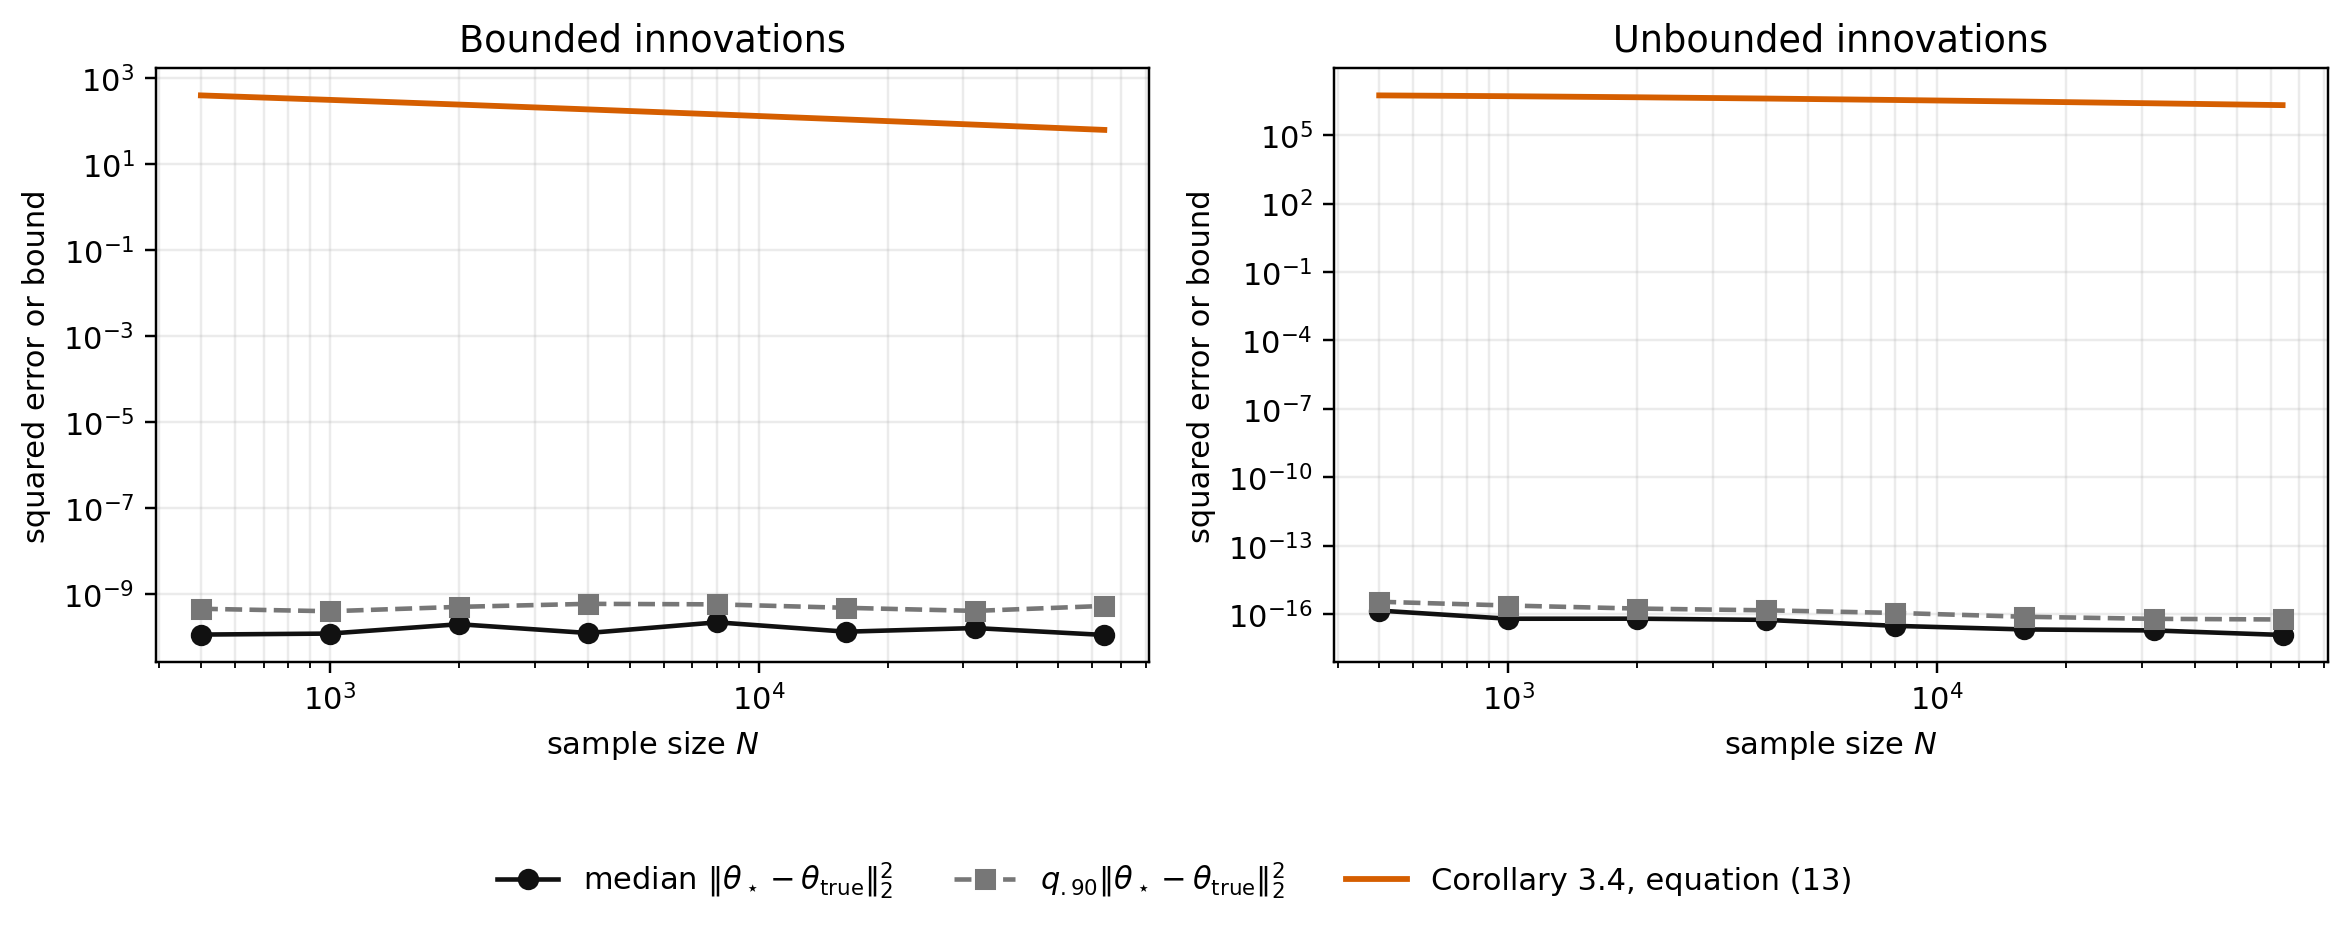

In [25]:
def make_parameter_error_plot(
    summary: pd.DataFrame, output_dir: Path
) -> None:
    """Plot observed squared MEP errors and equation (13)."""

    figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.25))
    for axis, regime in zip(axes, ("bounded", "unbounded")):
        block = summary[summary["regime"].eq(regime)].sort_values("N")
        axis.loglog(
            block["N"],
            block["median_squared_parameter_error"],
            "o-",
            color="#111111",
            label=r"median $\|\theta_\star-\theta_{\rm true}\|_2^2$",
        )
        axis.loglog(
            block["N"],
            block["q90_squared_parameter_error"],
            "s--",
            color="#777777",
            label=r"$q_{.90}\|\theta_\star-\theta_{\rm true}\|_2^2$",
        )
        axis.loglog(
            block["N"],
            block["corollary_3_4_equation_13"],
            color="#D55E00",
            linewidth=1.9,
            label="Corollary 3.4, equation (13)",
        )
        axis.set_title(f"{regime.capitalize()} innovations")
        axis.set_xlabel(r"sample size $N$")
        axis.set_ylabel("squared error or bound")
        axis.grid(True, which="both", alpha=0.25)

    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
    figure.tight_layout(rect=(0, 0.12, 1, 1))
    for extension in ("pdf", "png"):
        figure.savefig(
            output_dir / f"gibbs_parameter_corollary34.{extension}",
            dpi=220,
            bbox_inches="tight",
        )
    plt.show()
    plt.close(figure)


make_parameter_error_plot(gibbs_summary, OUTPUT_DIR)


## 20. Two Gibbs posterior plots

A small error in the posterior mean does not always mean the posterior is concentrated near the true parameter. To see this, we plot the following quantity for the first $N=1000$ data set in each case:

$$
-\lambda_N\left(
\widehat{\mathcal L}_N(\theta)-\min_\vartheta\widehat{\mathcal L}_N(\vartheta)
\right).
$$

A nearly flat surface means the data change the uniform prior very little. The star marks $\theta_{\rm true}$ and the circle marks the posterior mean. The paper table still uses all 40 data sets.


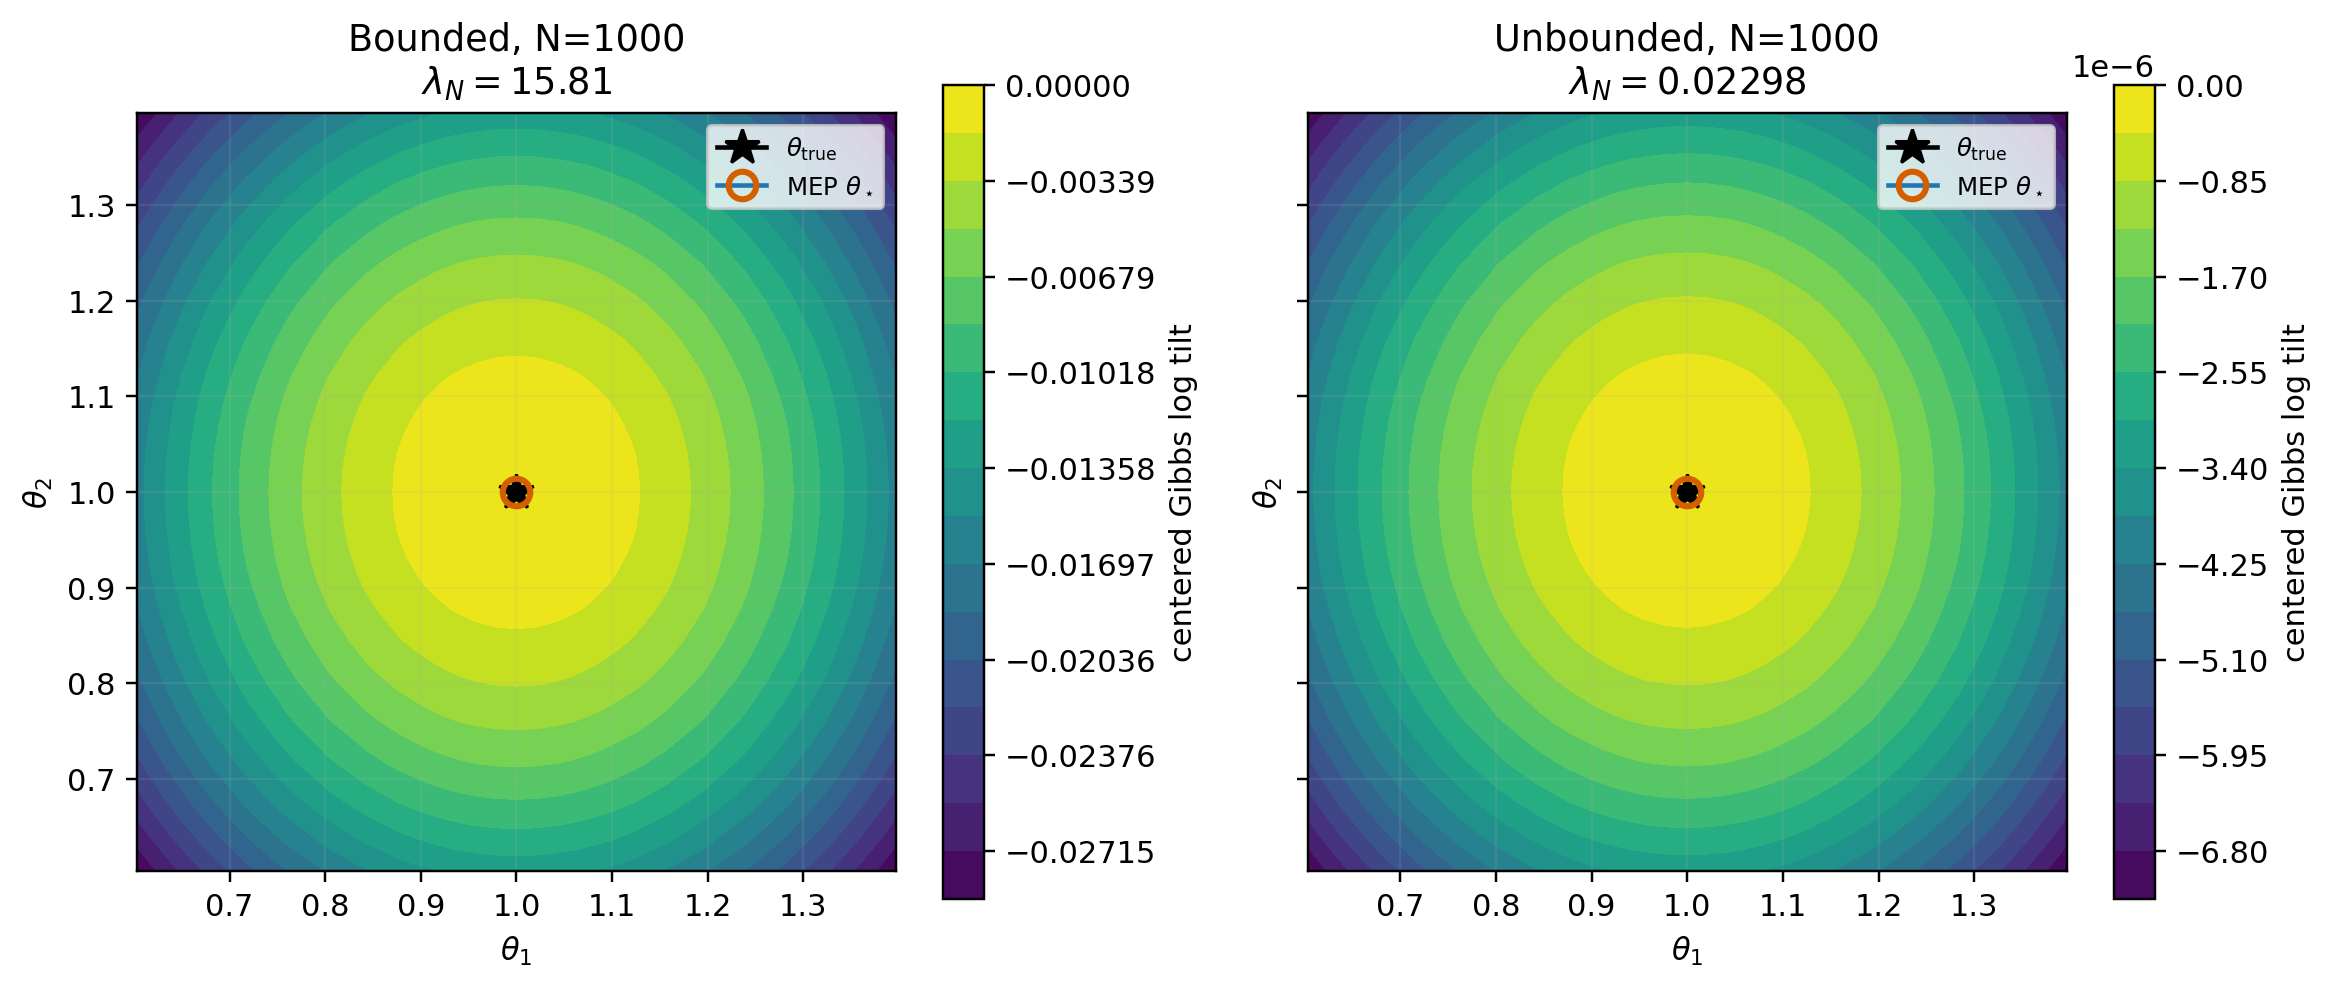

In [26]:
def make_posterior_geometry_plot(
    snapshots: dict[str, dict[str, object]],
    theta_nodes: np.ndarray,
    output_dir: Path,
) -> None:
    """Plot the centered empirical-risk tilt for representative posteriors."""

    axis_1 = np.unique(theta_nodes[:, 0])
    axis_2 = np.unique(theta_nodes[:, 1])
    grid_1, grid_2 = np.meshgrid(axis_1, axis_2, indexing="ij")
    figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.5), sharex=True, sharey=True)

    for axis, regime in zip(axes, ("bounded", "unbounded")):
        snapshot = snapshots[regime]
        empirical_risk = np.asarray(snapshot["empirical_risk"], dtype=float)
        temperature = float(snapshot["temperature"])
        posterior = snapshot["posterior"]
        mean = np.asarray(posterior["mean"], dtype=float)
        centered_log_tilt = -temperature * (
            empirical_risk - empirical_risk.min()
        )
        surface = centered_log_tilt.reshape(len(axis_1), len(axis_2))
        levels = np.linspace(float(surface.min()), 0.0, 18)
        contour = axis.contourf(
            grid_1, grid_2, surface, levels=levels, cmap="viridis"
        )
        figure.colorbar(contour, ax=axis, label="centered Gibbs log tilt")
        axis.plot(
            theta_true[0],
            theta_true[1],
            marker="*",
            color="black",
            markersize=12,
            label=r"$\theta_{\rm true}$",
        )
        axis.plot(
            mean[0],
            mean[1],
            marker="o",
            markerfacecolor="none",
            markeredgecolor="#D55E00",
            markeredgewidth=2.0,
            markersize=9,
            label=r"MEP $\theta_\star$",
        )
        axis.set_title(
            f"{regime.capitalize()}, N=1000\n"
            + rf"$\lambda_N={temperature:.4g}$"
        )
        axis.set_xlabel(r"$\theta_1$")
        axis.set_ylabel(r"$\theta_2$")
        axis.set_aspect("equal", adjustable="box")
        axis.grid(alpha=0.15)
        axis.legend(loc="upper right", fontsize=8)

    figure.tight_layout()
    for extension in ("pdf", "png"):
        figure.savefig(
            output_dir / f"gibbs_posterior_geometry_N1000.{extension}",
            dpi=220,
            bbox_inches="tight",
        )
    plt.show()
    plt.close(figure)


make_posterior_geometry_plot(posterior_snapshots, theta_nodes, OUTPUT_DIR)


## 21. Temperature over sample size

This plot shows $\lambda_N$ for B and U. In B, $\lambda_N=\sqrt N/2$. In U, the extra $2L(\ln N)^{3/2}$ in the denominator makes it much smaller. This helps explain why the U posterior can stay close to the symmetric prior even when its mean has a small error.


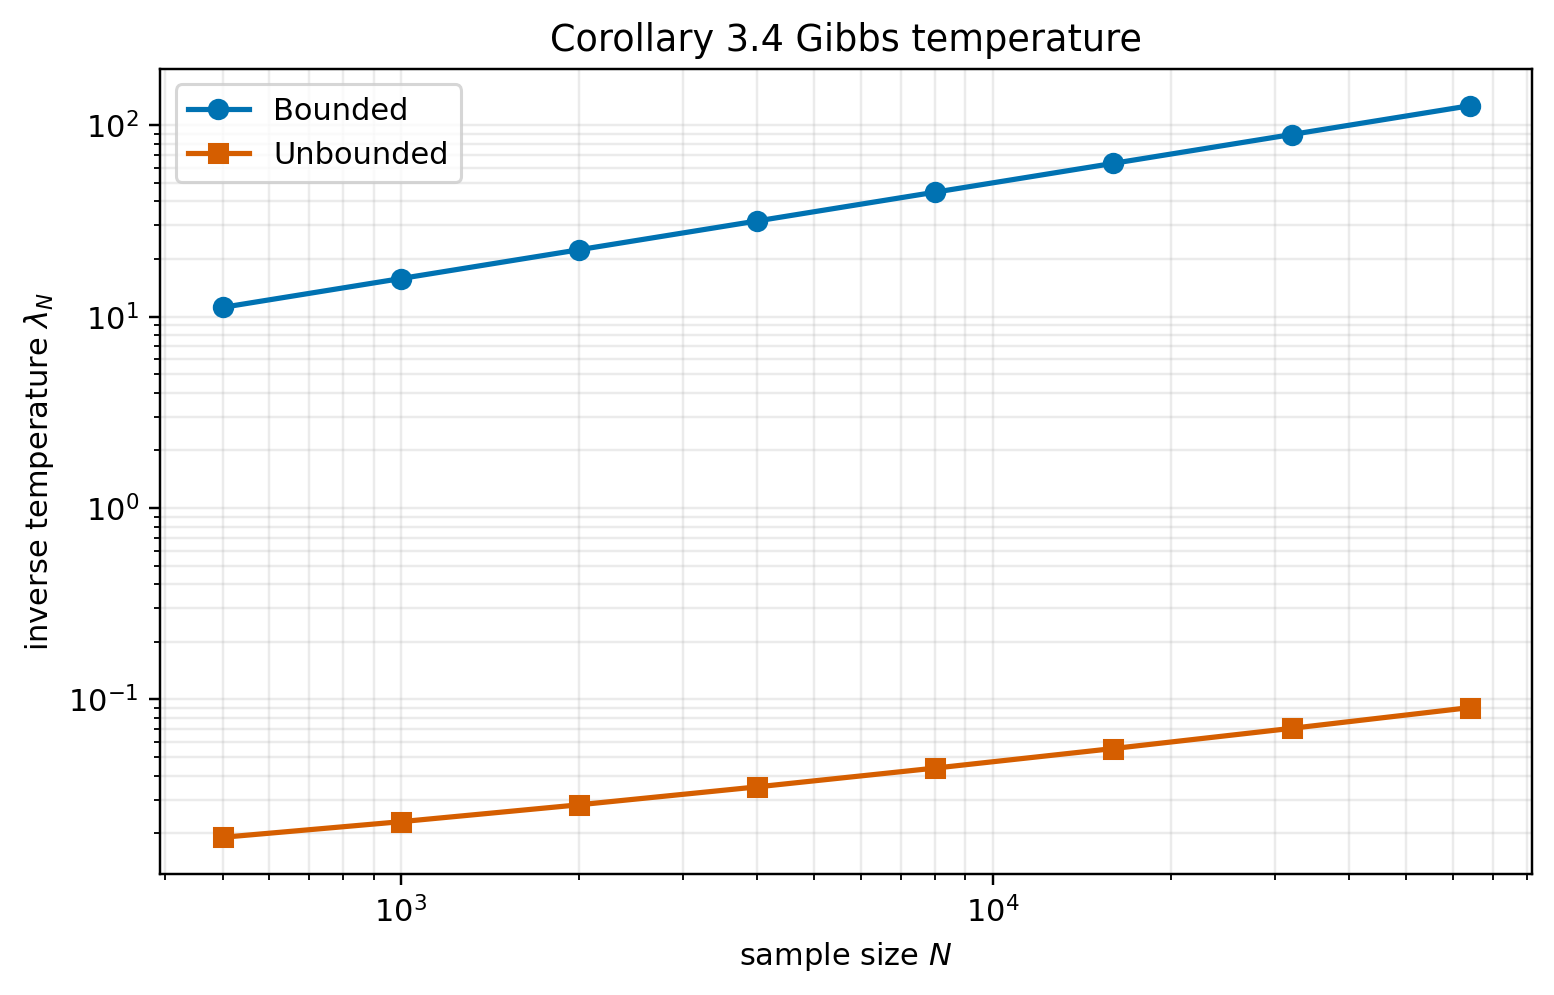

In [27]:
figure, axis = plt.subplots(figsize=(7.2, 4.7))
for regime, color, marker in (
    ("bounded", "#0072B2", "o"),
    ("unbounded", "#D55E00", "s"),
):
    block = temperature_schedule[
        temperature_schedule["regime"].eq(regime)
    ].sort_values("N")
    axis.loglog(
        block["N"],
        block["lambda_N"],
        marker=marker,
        color=color,
        linewidth=1.7,
        label=regime.capitalize(),
    )
axis.set_xlabel(r"sample size $N$")
axis.set_ylabel(r"inverse temperature $\lambda_N$")
axis.set_title("Corollary 3.4 Gibbs temperature")
axis.grid(True, which="both", alpha=0.25)
axis.legend()
figure.tight_layout()
for extension in ("pdf", "png"):
    figure.savefig(
        OUTPUT_DIR / f"gibbs_temperature_schedule.{extension}",
        dpi=220,
        bbox_inches="tight",
    )
plt.show()
plt.close(figure)


## 22. Finding $\bar N$ using $N_g=4$

The paper uses the 90th percentile of squared errors from a separate experiment at $N_g=4$:

$$
e_{.90}(4)
=q_{.90}\!\left(
\|\theta_\star(D,4)-\theta_{\rm true}\|_2^2
\right).
$$

We find the smallest integer $\bar N>4$ for which

$$
\operatorname{Eq.(13)}(\bar N)<e_{.90}(4).
$$

Because $\bar N$ is very large, we first solve for $x=\ln N$ using

$$
\ln\!\left(\frac{LC_{\rm or}}{m_\Theta}\right)
+(r+1)\ln x-\frac{x}{2}=\ln e_{.90}(4).
$$

Then `Decimal` is used to find the integer and check both sides:

$$
\operatorname{Eq.(13)}(\bar N)<e_{.90}(4)
\leq\operatorname{Eq.(13)}(\bar N-1).
$$


In [28]:
def decimal_log_equation_13(
    n: int, coefficient: Decimal, log_power: Decimal
) -> Decimal:
    """Evaluate log of equation (13) with arbitrary precision."""

    decimal_n = Decimal(n)
    return (
        coefficient.ln()
        + log_power * decimal_n.ln().ln()
        - decimal_n.ln() / Decimal(2)
    )


def exact_equation_13_nbar(
    constants34: dict[str, float],
    m_theta: float,
    threshold: float,
    N_g: int,
) -> dict[str, object]:
    """Find and verify the smallest integer N_bar>N_g below threshold."""

    coefficient = Decimal(
        str(constants34["rate_L"] * constants34["C_or_mep"] / m_theta)
    )
    log_power = Decimal(str(constants34["rate_r"] + 1.0))
    target = Decimal(str(threshold))

    with localcontext() as context:
        context.prec = 120
        log_n = max(
            Decimal(10),
            Decimal(2)
            * (
                coefficient.ln()
                - target.ln()
                + log_power * Decimal(10).ln()
            ),
        )
        for _ in range(200):
            residual = (
                coefficient.ln()
                + log_power * log_n.ln()
                - log_n / Decimal(2)
                - target.ln()
            )
            derivative = log_power / log_n - Decimal(1) / Decimal(2)
            update = residual / derivative
            log_n -= update
            if abs(update) < Decimal("1e-90"):
                break
        required_digits = max(
            120, int(log_n / Decimal(10).ln()) + 120
        )

    with localcontext() as context:
        context.prec = required_digits
        for _ in range(300):
            residual = (
                coefficient.ln()
                + log_power * log_n.ln()
                - log_n / Decimal(2)
                - target.ln()
            )
            derivative = log_power / log_n - Decimal(1) / Decimal(2)
            update = residual / derivative
            log_n -= update
            if abs(update) < Decimal(1).scaleb(-(required_digits - 30)):
                break

        n_bar = max(
            N_g + 1,
            int(log_n.exp().to_integral_value(rounding=ROUND_FLOOR)) + 1,
        )
        log_target = target.ln()

        def is_strict(candidate: int) -> bool:
            return (
                decimal_log_equation_13(candidate, coefficient, log_power)
                < log_target
            )

        while n_bar > N_g + 1 and is_strict(n_bar - 1):
            n_bar -= 1
        while not is_strict(n_bar):
            n_bar += 1

        value_at_nbar = decimal_log_equation_13(
            n_bar, coefficient, log_power
        ).exp()
        value_at_previous = decimal_log_equation_13(
            n_bar - 1, coefficient, log_power
        ).exp()
        if not (value_at_nbar < target <= value_at_previous):
            raise AssertionError("The adjacent-integer N_bar test failed.")

    return {
        "N_bar_exact": str(n_bar),
        "log10_N_bar": math.log10(n_bar),
        "equation_13_at_N_bar": format(value_at_nbar, ".24E"),
        "equation_13_at_N_bar_minus_1": format(value_at_previous, ".24E"),
        "threshold_minus_equation_13_at_N_bar": format(
            target - value_at_nbar, ".24E"
        ),
        "equation_13_at_N_bar_minus_1_minus_threshold": format(
            value_at_previous - target, ".24E"
        ),
        "strict_adjacent_integer_test": True,
    }


## 23. Separate $N_g=4$ experiment

`run_N_g_benchmark` generates 1000 new length-four data sets for each noise case, using seed offsets `500004` for B and `600004` for U. We apply the same loss, 1089-node integration, and Gibbs temperature as in the main experiment.

These data sets are separate from the main experiment. Their 90th-percentile errors are used to find $\bar N$.


In [29]:
def run_N_g_benchmark(
    settings: Settings,
    system: System,
    theta_nodes: np.ndarray,
    prior_weights: np.ndarray,
    bounded_c34: dict[str, float],
    unbounded_c34: dict[str, float],
) -> pd.DataFrame:
    """Generate independent N_g records and their squared Gibbs MEP errors."""

    rows: list[dict[str, float | int | str]] = []
    seed_offsets = {"bounded": 500004, "unbounded": 600004}
    for regime in ("bounded", "unbounded"):
        rng = np.random.default_rng(settings.seed + seed_offsets[regime])
        for trial in range(settings.N_g_trials):
            y, u = simulate_data(
                regime, settings.N_g, rng, settings, system
            )
            base, feature = finite_affine_features(system, u)
            residual_zero = y - base
            empirical_risk = quadratic_empirical_risk_grid(
                residual_zero,
                feature,
                theta_nodes,
                (settings.N_g,),
            )[0]
            temperature = gibbs_temperature(
                regime, settings.N_g, bounded_c34, unbounded_c34
            )
            posterior = gibbs_posterior(
                empirical_risk, theta_nodes, prior_weights, temperature
            )
            mean = np.asarray(posterior["mean"], dtype=float)
            error = mean - theta_true
            rows.append(
                {
                    "regime": regime,
                    "trial": trial,
                    "N_g": settings.N_g,
                    "posterior_mean_theta_1": float(mean[0]),
                    "posterior_mean_theta_2": float(mean[1]),
                    "squared_parameter_error": float(error @ error),
                }
            )
    return pd.DataFrame(rows)


### Calculate the $N_g=4$ results and $\bar N$

We calculate the 90th-percentile error for B and U, find $\bar N$, and check the neighboring integers. The full values are saved in `gibbs_parameter_Nbar_q90.csv`.


In [30]:
print("Running 1,000 independent N_g=4 realizations per regime...")
N_g_trials = run_N_g_benchmark(
    settings,
    system,
    theta_nodes,
    prior_weights,
    bounded_c34,
    unbounded_c34,
)

nbar_rows: list[dict[str, object]] = []
for regime, block in N_g_trials.groupby("regime"):
    threshold = float(
        np.quantile(block["squared_parameter_error"].to_numpy(dtype=float), 0.90)
    )
    nbar_rows.append(
        {
            "regime": regime,
            "error_statistic": "q90 squared parameter error",
            "N_g": settings.N_g,
            "q90_squared_parameter_error_at_N_g": threshold,
            **exact_equation_13_nbar(
                constants34_by_regime[regime],
                m_theta_by_regime[regime],
                threshold,
                settings.N_g,
            ),
        }
    )

nbar_table = pd.DataFrame(nbar_rows)
N_g_trials.to_csv(
    OUTPUT_DIR / "gibbs_parameter_Ng4_trials.csv", index=False
)
nbar_table.to_csv(
    OUTPUT_DIR / "gibbs_parameter_Nbar_q90.csv", index=False
)
nbar_table[
    [
        "regime",
        "q90_squared_parameter_error_at_N_g",
        "N_bar_exact",
        "log10_N_bar",
        "strict_adjacent_integer_test",
    ]
]


Running 1,000 independent N_g=4 realizations per regime...


,regime,q90_squared_parameter_error_at_N_g,N_bar_exact,log10_N_bar,strict_adjacent_integer_test
0,bounded,3.09567835e-10,95549215751180743400515968677,28.9802271,True
1,unbounded,1.59264413e-14,1347796644257159275166391250077721436168061567...,50.1296244,True


## 24. Check the integration grid

The main posterior uses 1089 nodes. We repeat the first $N=1000$ example for B and U with 17 nodes in each of the three intervals, giving $51^2=2601$ nodes. We compare the posterior means and squared errors while keeping the data, loss, and temperature unchanged.


In [31]:
fine_theta_nodes, fine_prior_weights = prior_quadrature(
    settings, order_per_panel=17
)
quadrature_refinement_rows = []
for regime in ("bounded", "unbounded"):
    snapshot = posterior_snapshots[regime]
    residual_zero = np.asarray(snapshot["residual_zero"], dtype=float)
    feature = np.asarray(snapshot["feature"], dtype=float)
    n = int(snapshot["N"])
    fine_risk = quadratic_empirical_risk_grid(
        residual_zero,
        feature,
        fine_theta_nodes,
        (n,),
    )[0]
    fine_posterior = gibbs_posterior(
        fine_risk,
        fine_theta_nodes,
        fine_prior_weights,
        float(snapshot["temperature"]),
    )
    coarse_mean = np.asarray(snapshot["posterior"]["mean"], dtype=float)
    fine_mean = np.asarray(fine_posterior["mean"], dtype=float)
    coarse_error = float(np.sum((coarse_mean - theta_true) ** 2))
    fine_error = float(np.sum((fine_mean - theta_true) ** 2))
    quadrature_refinement_rows.append(
        {
            "regime": regime,
            "coarse_nodes": len(theta_nodes),
            "fine_nodes": len(fine_theta_nodes),
            "mean_difference_norm": float(np.linalg.norm(fine_mean - coarse_mean)),
            "squared_error_difference": abs(fine_error - coarse_error),
        }
    )

quadrature_refinement = pd.DataFrame(quadrature_refinement_rows)
quadrature_refinement.to_csv(
    OUTPUT_DIR / "gibbs_quadrature_refinement.csv", index=False
)
quadrature_refinement


,regime,coarse_nodes,fine_nodes,mean_difference_norm,squared_error_difference
0,bounded,1089,2601,5.55111512e-16,3.82155181e-21
1,unbounded,1089,2601,7.02166694e-16,1.82628838e-24


## 25. Why the prior center matters

The prior is centered at $\theta_{\rm true}$. If the Gibbs weights only change it a little, the posterior mean may be very close to the true parameter even when the posterior is still spread out. This matters especially for case U.

The prior covariance has trace $2(0.4^2/3)$. For the first $N=1000$ posterior in each case, we compare this with the posterior covariance trace and display KL, the range of Gibbs log weights, and the squared error.


In [32]:
prior_covariance_trace = 2.0 * settings.prior_half_width**2 / 3.0
centering_rows = []
for regime in ("bounded", "unbounded"):
    snapshot = posterior_snapshots[regime]
    posterior = snapshot["posterior"]
    empirical_risk = np.asarray(snapshot["empirical_risk"], dtype=float)
    temperature = float(snapshot["temperature"])
    mean = np.asarray(posterior["mean"], dtype=float)
    covariance = np.asarray(posterior["covariance"], dtype=float)
    centering_rows.append(
        {
            "regime": regime,
            "N": int(snapshot["N"]),
            "posterior_KL": float(posterior["KL"]),
            "Gibbs_log_tilt_range": temperature * float(np.ptp(empirical_risk)),
            "prior_covariance_trace": prior_covariance_trace,
            "posterior_covariance_trace": float(np.trace(covariance)),
            "posterior/prior_trace_ratio": float(np.trace(covariance))
            / prior_covariance_trace,
            "squared_MEP_error": float(np.sum((mean - theta_true) ** 2)),
        }
    )

prior_centering_check = pd.DataFrame(centering_rows)
prior_centering_check.to_csv(
    OUTPUT_DIR / "gibbs_prior_centering_check.csv", index=False
)
prior_centering_check


,regime,N,posterior_KL,Gibbs_log_tilt_range,prior_covariance_trace,posterior_covariance_trace,posterior/prior_trace_ratio,squared_MEP_error
0,bounded,1000,1.92451773e-05,0.0288475204,0.106666667,0.106250449,0.996097957,2.16158039e-11
1,unbounded,1000,1.2001867e-12,7.22431287e-06,0.106666667,0.106666563,0.999999025,1.53455591e-17


## 26. Final checks

The last cell checks the system, prior nodes, trial counts, equation (13) values, $\bar N$, and integration results. Small differences between computers can change the final digits of simulated errors, so we compare the displayed errors to three significant digits.

We save the settings, matrices, constants, and check results in a JSON file.


In [33]:
expected_paper = pd.DataFrame(
    [
        {
            "case": "B",
            "N": 1000,
            "median": 1.200070629257488e-10,
            "q90": 3.96716669384056e-10,
            "equation_13": 313.2484017005403,
        },
        {
            "case": "B",
            "N": 64000,
            "median": 1.1135303112705606e-10,
            "q90": 5.278984928391885e-10,
            "equation_13": 62.730341463983194,
        },
        {
            "case": "U",
            "N": 1000,
            "median": 6.322083949627892e-17,
            "q90": 2.4065389649927316e-16,
            "equation_13": 5122688.40891126,
        },
        {
            "case": "U",
            "N": 64000,
            "median": 1.2290600012496366e-17,
            "q90": 5.87117409064533e-17,
            "equation_13": 2080199.0343342994,
        },
    ]
)
computed_paper = paper_table.rename(
    columns={
        "median_squared_parameter_error": "median",
        "q90_squared_parameter_error": "q90",
        "corollary_3_4_equation_13": "equation_13",
    }
).reset_index(drop=True)

assert np.allclose(system.A_theta(theta_true), A_g)
assert np.allclose(prior_corner_radii, 0.25)
assert np.linalg.norm(A_g @ A_g, ord="fro") > 0.0
assert maximum_affine_error < 2.0e-13
assert len(theta_nodes) == 1089 and np.isclose(prior_weights.sum(), 1.0)
assert len(fine_theta_nodes) == 2601 and np.isclose(fine_prior_weights.sum(), 1.0)
assert len(gibbs_trials) == 2 * settings.monte_carlo_trials * len(settings.sample_sizes)
assert len(N_g_trials) == 2 * settings.N_g_trials
assert len(paper_table) == 4
assert bool(nbar_table["strict_adjacent_integer_test"].all())
assert float(quadrature_refinement["mean_difference_norm"].max()) < 1.0e-12

np.testing.assert_array_equal(
    computed_paper[["case", "N"]].to_numpy(),
    expected_paper[["case", "N"]].to_numpy(),
)

# Compare the simulated errors to three significant digits.
computed_error_display = np.vectorize(lambda value: f"{value:.2e}")(
    computed_paper[["median", "q90"]].to_numpy(dtype=float)
)
expected_error_display = np.vectorize(lambda value: f"{value:.2e}")(
    expected_paper[["median", "q90"]].to_numpy(dtype=float)
)
np.testing.assert_array_equal(computed_error_display, expected_error_display)

# Check equation (13) more closely.
np.testing.assert_allclose(
    computed_paper["equation_13"].to_numpy(dtype=float),
    expected_paper["equation_13"].to_numpy(dtype=float),
    rtol=5.0e-12,
    atol=0.0,
)

# Compare log10(N_bar) since small simulation changes affect its last digits.
expected_log10_nbar = {
    "bounded": 28.980227126803566,
    "unbounded": 50.12962437073103,
}
for regime, expected_log10 in expected_log10_nbar.items():
    computed_log10 = float(
        nbar_table.loc[nbar_table["regime"].eq(regime), "log10_N_bar"].iloc[0]
    )
    assert math.isclose(computed_log10, expected_log10, rel_tol=0.0, abs_tol=5.0e-5)

assert np.isclose(m_theta_by_regime["bounded"], 0.009336541427049065)
assert np.isclose(m_theta_by_regime["unbounded"], 0.001750645282609639)
assert np.isclose(bounded_c34["C_or_mep"], 13.388685770580974)
assert np.isclose(unbounded_c34["rate_L"], 37.9041003438053)
assert np.isclose(unbounded_c34["C_or_mep"], 59.65784296426446)

all_corollary_rows = []
for regime, values in constants34_by_regime.items():
    all_corollary_rows.extend(
        {
            "group": f"corollary34_{regime}",
            "constant": name,
            "value": value,
        }
        for name, value in values.items()
    )
pd.concat(
    [scalar_constants, pd.DataFrame(all_corollary_rows)], ignore_index=True
).to_csv(OUTPUT_DIR / "gibbs_constants.csv", index=False)

check_results = {
    "settings": asdict(settings),
    "dimensions": {"state": 3, "input": 2, "output": 2, "parameter": 2},
    "theta_true": theta_true.tolist(),
    "A_g": A_g.tolist(),
    "D_1": D_1.tolist(),
    "D_2": D_2.tolist(),
    "B": B.tolist(),
    "C": C.tolist(),
    "spectral_radius_over_prior": float(prior_corner_radii.max()),
    "A_true_is_non_nilpotent": True,
    "posterior": {
        "definition": (
            "rho_Gibbs(dtheta) proportional to exp(-lambda_N empirical quadratic loss(theta)) pi(dtheta)"
        ),
        "quadrature_nodes": len(theta_nodes),
        "quadrature_weight_sum": float(prior_weights.sum()),
        "posterior_uses_Monte_Carlo": False,
    },
    "corollary34": {
        "m_Theta": m_theta_by_regime,
        "bounded": bounded_c34,
        "unbounded": unbounded_c34,
        "equation_13_is_squared_error_bound": True,
    },
    "main_independent_data_realizations_per_regime": settings.monte_carlo_trials,
    "N_g_4_independent_data_realizations_per_regime": settings.N_g_trials,
    "quadrature_refinement_nodes": len(fine_theta_nodes),
    "maximum_posterior_mean_change_under_refinement": float(
        quadrature_refinement["mean_difference_norm"].max()
    ),
    "all_Nbar_adjacent_integer_tests_pass": True,
    "paper_values_reproduced": True,
    "interpretation_warning": (
        "The uniform prior is symmetric about theta_true, so a weakly tilted Gibbs posterior can have a very accurate mean without strong concentration."
    ),
}
(OUTPUT_DIR / "gibbs_checks.json").write_text(
    json.dumps(check_results, indent=2), encoding="utf-8"
)

print("All checks passed. Paper values were reproduced.")
print("Generated files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(" -", path.name)


All checks passed. Paper values were reproduced.
Generated files:
 - gibbs_constants.csv
 - gibbs_parameter_Nbar_q90.csv
 - gibbs_parameter_Ng4_trials.csv
 - gibbs_parameter_corollary34.pdf
 - gibbs_parameter_corollary34.png
 - gibbs_parameter_results_all_N.csv
 - gibbs_parameter_paper_table.csv
 - gibbs_parameter_trials.csv
 - gibbs_posterior_geometry_N1000.pdf
 - gibbs_posterior_geometry_N1000.png
 - gibbs_prior_centering_check.csv
 - gibbs_prior_quadrature.csv
 - gibbs_quadrature_refinement.csv
 - gibbs_system_constants.csv
 - gibbs_temperature_and_equation13.csv
 - gibbs_temperature_schedule.pdf
 - gibbs_temperature_schedule.png
 - gibbs_checks.json
